# NHANES multi-label health risk classifier: cleaning -> ablation -> modelling
12 typable features -> 3 independent binary risks (hypertension, diabetes, high cholesterol), probabilistic output (binary relevance, one CatBoost per target).

Pipeline: raw CDC `.xpt` -> cleaning -> split -> leakage and feature ablations -> model comparison -> final models + out-of-fold soft labels -> evaluation -> ONNX.
Cycle: NHANES 2017–Mar 2020 only (family history and activity questions exist only there; oscillometric BP device is consistent since 2017).

## 0. Setup

In [1]:
import os, json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings('ignore'); pd.set_option('display.width', 200)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

NJ = os.cpu_count()
RAW, EXTRA, OUT = 'data/nhanes_raw_2017_2020/', 'data/nhanes_extra/', 'data/final/'
os.makedirs(OUT, exist_ok=True); os.makedirs('models', exist_ok=True)

FEATS = ['age', 'male', 'bmi', 'sbp', 'dbp', 'smoker', 'waist', 'hdl', 'fam_dm', 'fam_mi', 'vig_rec', 'mod_rec']
BASE = ['age', 'male', 'bmi', 'sbp', 'dbp', 'smoker', 'waist', 'hdl']
COMMON = ['height', 'weight', 'sedentary_min', 'alc_days', 'alc_per_day', 'sleep_h']
FAM = ['fam_dm', 'fam_mi', 'vig_rec', 'mod_rec', 'vig_work', 'mod_work']
TG = {'hipertensi': 'htn', 'diabetes': 'dm_comp', 'kolesterol_tinggi': 'hichol'}
CB = dict(iterations=500, learning_rate=0.05, depth=4, random_seed=0, verbose=0, thread_count=NJ, allow_writing_files=False)

## 1. Cleaning

In [2]:
def rd(f, d=RAW):
    return pd.read_sas(f'{d}{f}.xpt', format='xport').assign(SEQN=lambda x: x.SEQN.astype(int)).set_index('SEQN')
yn = lambda s: s.map({1: 1, 2: 0})

demo, bmx, bp, tc, hdl, ghb, glu, bpq, diq, smq = [rd(f) for f in
    ['P_DEMO', 'P_BMX', 'P_BPXO', 'P_TCHOL', 'P_HDL', 'P_GHB', 'P_GLU', 'P_BPQ', 'P_DIQ', 'P_SMQ']]
paq, alq, slq, mcq = [rd(f, EXTRA) for f in ['P_PAQ', 'P_ALQ', 'P_SLQ', 'P_MCQ']]

d = (demo[['RIAGENDR', 'RIDAGEYR']].join(bmx[['BMXBMI', 'BMXWAIST', 'BMXHT', 'BMXWT']]).join(tc.LBXTC).join(hdl.LBDHDD)
     .join(ghb.LBXGH).join(glu.LBXGLU).join(bpq[['BPQ020', 'BPQ080']]).join(diq.DIQ010).join(smq.SMQ020.rename('smoker')))
d['sbp'] = bp[['BPXOSY1', 'BPXOSY2', 'BPXOSY3']].mean(axis=1)   # mean of up to 3 oscillometric readings
d['dbp'] = bp[['BPXODI1', 'BPXODI2', 'BPXODI3']].mean(axis=1)

# cohort funnel
REQ = ['sbp', 'dbp', 'BMXBMI', 'LBXTC', 'LBDHDD', 'LBXGH', 'BPQ020', 'BPQ080', 'DIQ010', 'smoker']
adults = d[d.RIDAGEYR >= 18]
cohort = adults.dropna(subset=REQ)
print(pd.Series({'all participants (DEMO)': len(demo), 'adults >= 18': len(adults),
                 'with BP': int(adults.sbp.notna().sum()), 'complete on required fields': len(cohort)}).to_string())

all participants (DEMO)        15560
adults >= 18                    9693
with BP                         8024
complete on required fields     7425


In [3]:
df = cohort.rename(columns={'RIAGENDR': 'sex', 'RIDAGEYR': 'age', 'BMXBMI': 'bmi', 'BMXWAIST': 'waist', 'BMXHT': 'height',
                            'BMXWT': 'weight', 'LBXTC': 'chol', 'LBDHDD': 'hdl', 'LBXGH': 'hba1c', 'LBXGLU': 'glucose'}).copy()
df['male'] = (df.sex == 1).astype(int)
df['smoker'] = df.smoker.map({1: 1, 2: 0})                       # ever smoked >= 100 cigarettes (SMQ020)

# labels
df['htn'] = df.BPQ020.map({1: 1, 2: 0})                          # told by a doctor: high blood pressure
df['hichol'] = df.BPQ080.map({1: 1, 2: 0})                       # told by a doctor: high cholesterol
df['dm_comp'] = ((df.DIQ010 == 1) | (df.hba1c >= 6.5) | (df.glucose >= 126)).astype(int)   # told OR HbA1c OR fasting glucose

# extra features
df['sedentary_min'] = paq.PAD680.where(~paq.PAD680.isin([7777, 9999]))
nd = alq.ALQ111 == 2
df['alc_days'] = alq.ALQ121.where(~alq.ALQ121.isin([77, 99])).where(~nd, 0)
df['alc_per_day'] = alq.ALQ130.where(~alq.ALQ130.isin([777, 999])).where(~nd, 0)
df['sleep_h'] = slq.SLD012
df['fam_dm'], df['fam_mi'] = yn(mcq.MCQ300C), yn(mcq.MCQ300A)    # close relative with diabetes / heart attack
df['vig_rec'], df['mod_rec'] = yn(paq.PAQ650), yn(paq.PAQ665)    # vigorous / moderate recreational activity
df['vig_work'], df['mod_work'] = yn(paq.PAQ605), yn(paq.PAQ620)
df = df.reset_index()
LAB = list(TG.values())
print(len(df), 'rows'); print(df[LAB].agg(['mean', lambda s: s.isna().sum()]).set_axis(['positive rate', 'missing'], axis=0).round(3))

7425 rows
                 htn  dm_comp  hichol
positive rate   0.37    0.194   0.351
missing        11.00    0.000  48.000


## 2. Split (70/15/15, stratified on the label combination)

In [4]:
ALL = ['SEQN'] + sorted(set(FEATS + COMMON + FAM + ['chol', 'hba1c', 'glucose'])) + LAB
sub = df[ALL].reset_index(drop=True)
key = sub.htn.fillna(0).astype(int) * 4 + sub.dm_comp * 2 + sub.hichol.fillna(0).astype(int)
tr, rest = train_test_split(sub, test_size=0.30, stratify=key.values, random_state=42)
va, te = train_test_split(rest, test_size=0.50, random_state=42)
print(len(tr), len(va), len(te))
print(pd.DataFrame({n: x[LAB].mean() for n, x in [('train', tr), ('val', va), ('test', te)]}).round(3))

5197 1114 1114
         train    val   test
htn      0.370  0.361  0.381
dm_comp  0.195  0.189  0.199
hichol   0.350  0.352  0.350


## 3. Overview (train)

In [5]:
print(tr[FEATS].describe().T[['count', 'mean', 'min', '50%', 'max']].round(2))
print('\nmissing % :', (tr[FEATS].isna().mean() * 100).round(1)[lambda s: s > 0].to_dict())

          count    mean    min     50%    max
age      5197.0   49.56  18.00   51.00   80.0
male     5197.0    0.50   0.00    0.00    1.0
bmi      5197.0   29.80  14.60   28.60   80.6
sbp      5197.0  123.96  79.67  121.33  217.0
dbp      5197.0   74.31  41.67   73.67  135.0
smoker   5195.0    0.41   0.00    0.00    1.0
waist    5095.0  100.46  56.40   99.00  187.5
hdl      5197.0   53.37  11.00   51.00  189.0
fam_dm   4894.0    0.48   0.00    0.00    1.0
fam_mi   4852.0    0.13   0.00    0.00    1.0
vig_rec  5197.0    0.25   0.00    0.00    1.0
mod_rec  5195.0    0.42   0.00    0.00    1.0

missing % : {'waist': 2.0, 'fam_dm': 5.8, 'fam_mi': 6.6}


## 4. Ablations (5-fold CV AUC on train only; test set untouched)
**4a. Leakage check.** Variables that define a label must not be inputs. Adding them should inflate AUC; the honest setup leaves them out.

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
XGB = lambda: XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                            eval_metric='auc', n_jobs=NJ)
def cv_auc(model, feats, y):
    x = tr.dropna(subset=[y])
    p = cross_val_predict(model, x[feats], x[y].astype(int), cv=cv, method='predict_proba')[:, 1]
    return roc_auc_score(x[y], p)

NOBP = [c for c in FEATS if c not in ('sbp', 'dbp')]
rows = [
    ('hipertensi', 'final 12 features', cv_auc(XGB(), FEATS, 'htn')),
    ('hipertensi', 'without BP (sbp, dbp)', cv_auc(XGB(), NOBP, 'htn')),
    ('diabetes', 'final 12 features', cv_auc(XGB(), FEATS, 'dm_comp')),
    ('diabetes', '+ HbA1c + glucose (they define the label)', cv_auc(XGB(), FEATS + ['hba1c', 'glucose'], 'dm_comp')),
    ('kolesterol_tinggi', 'final 12 features', cv_auc(XGB(), FEATS, 'hichol')),
    ('kolesterol_tinggi', '+ total cholesterol', cv_auc(XGB(), FEATS + ['chol'], 'hichol')),
]
print(pd.DataFrame(rows, columns=['target', 'input set', 'CV AUC']).round(3).to_string(index=False))
t = te.dropna(subset=['htn'])
print('\nrule BP >= 140/90 -> hypertension, test AUC:', round(roc_auc_score(t.htn, ((t.sbp >= 140) | (t.dbp >= 90)).astype(int)), 3))

           target                                 input set  CV AUC
       hipertensi                         final 12 features   0.813
       hipertensi                     without BP (sbp, dbp)   0.784
         diabetes                         final 12 features   0.824
         diabetes + HbA1c + glucose (they define the label)   0.970
kolesterol_tinggi                         final 12 features   0.765
kolesterol_tinggi                       + total cholesterol   0.780

rule BP >= 140/90 -> hypertension, test AUC: 0.641


**4b. Feature sets** (XGBoost, default params).

In [7]:
SETS = {'A base 8': BASE, 'B +common (height, weight, sedentary, alcohol, sleep)': BASE + COMMON,
        'C final 12 (+family history, recreational activity)': FEATS, 'D all': BASE + COMMON + FAM}
fs = pd.DataFrame({n: {t: cv_auc(XGB(), f, y) for t, y in TG.items()} for n, f in SETS.items()}).round(3)
print(fs.to_string())

                   A base 8  B +common (height, weight, sedentary, alcohol, sleep)  C final 12 (+family history, recreational activity)  D all
hipertensi            0.808                                                  0.807                                                0.813  0.811
diabetes              0.796                                                  0.795                                                0.824  0.825
kolesterol_tinggi     0.761                                                  0.759                                                0.765  0.763


**4c. Model comparison** on the final 12 features.

In [8]:
MODELS = {
    'LogReg': lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=2000)),
    'RandomForest': lambda: make_pipeline(SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=500, max_depth=10, min_samples_leaf=10, max_features=0.6, n_jobs=NJ, random_state=0)),
    'XGBoost': XGB,
    'LightGBM': lambda: LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, subsample=0.8, subsample_freq=1,
                                       colsample_bytree=0.8, n_jobs=NJ, verbose=-1),
    'CatBoost': lambda: CatBoostClassifier(**CB),
}
mc = pd.DataFrame({m: {t: cv_auc(f(), FEATS, y) for t, y in TG.items()} for m, f in MODELS.items()}).round(3)
print(mc.to_string())

                   LogReg  RandomForest  XGBoost  LightGBM  CatBoost
hipertensi          0.810         0.810    0.813     0.811     0.812
diabetes            0.822         0.818    0.824     0.820     0.821
kolesterol_tinggi   0.764         0.763    0.765     0.766     0.764


## 5. Final models
One CatBoost per target, trained on train rows that have the label. Out-of-fold probabilities on train act as soft labels for the LLM data step (no in-sample overfit).

In [9]:
models, soft = {}, {'train': pd.DataFrame({'SEQN': tr.SEQN}), 'val': pd.DataFrame({'SEQN': va.SEQN}), 'test': pd.DataFrame({'SEQN': te.SEQN})}
for name, y in TG.items():
    x = tr.dropna(subset=[y]); yi = x[y].astype(int)
    oof = pd.Series(np.nan, index=tr.index)
    oof.loc[x.index] = cross_val_predict(CatBoostClassifier(**CB), x[FEATS], yi, cv=cv, method='predict_proba')[:, 1]
    models[name] = CatBoostClassifier(**CB).fit(x[FEATS], yi)
    soft['train'][f'p_{name}'] = oof.values
    soft['val'][f'p_{name}'] = models[name].predict_proba(va[FEATS])[:, 1]
    soft['test'][f'p_{name}'] = models[name].predict_proba(te[FEATS])[:, 1]
    print(name, 'trained on', len(x), 'rows')

for n, x in [('train', tr), ('val', va), ('test', te)]:
    x[['SEQN'] + FEATS + LAB].to_csv(f'{OUT}{n}.csv', index=False); soft[n].to_csv(f'{OUT}teacher_{n}.csv', index=False)
json.dump({'features': FEATS, 'targets': LAB}, open(OUT + 'meta.json', 'w'), indent=1)
print('saved', sorted(os.listdir(OUT)))

hipertensi trained on 5192 rows


diabetes trained on 5197 rows


kolesterol_tinggi trained on 5167 rows
saved ['cards_sample.json', 'kd', 'meta.json', 'risk_levels.json', 'teacher_test.csv', 'teacher_train.csv', 'teacher_val.csv', 'test.csv', 'train.csv', 'val.csv']


## 6. Evaluation on test
Threshold-free: ROC-AUC (bootstrap 95% CI), PR-AUC, Brier. Threshold metrics at 0.5 and at the threshold maximizing F1 on validation.

In [10]:
def best_thr(y, p):
    ths = np.linspace(0.05, 0.95, 91); return ths[np.argmax([f1_score(y, p >= t) for t in ths])]
def boot_auc(y, p, n=1000):
    r = np.random.RandomState(0); y, p = np.asarray(y), np.asarray(p); s = []
    for _ in range(n):
        i = r.randint(0, len(y), len(y))
        if y[i].min() != y[i].max(): s.append(roc_auc_score(y[i], p[i]))
    return np.percentile(s, [2.5, 97.5])

base_rows, rows, P = [], [], {}
for name, y in TG.items():
    v, t = va.dropna(subset=[y]), te.dropna(subset=[y])
    pv, pt = models[name].predict_proba(v[FEATS])[:, 1], models[name].predict_proba(t[FEATS])[:, 1]
    P[name] = (t[y].values, pt)
    prev = t[y].mean(); base_rows.append(dict(target=name, prevalence=prev, majority_acc=max(prev, 1 - prev), auc_chance=0.5, prauc_chance=prev))
    thr = best_thr(v[y], pv); lo, hi = boot_auc(t[y], pt)
    for tag, th in [('0.5', 0.5), (f'val-F1 ({thr:.2f})', thr)]:
        pr = (pt >= th).astype(int)
        rows.append(dict(target=name, thr=tag, AUC=roc_auc_score(t[y], pt), AUC_CI=f'{lo:.3f}-{hi:.3f}',
                         PRAUC=average_precision_score(t[y], pt), Brier=brier_score_loss(t[y], pt),
                         Acc=accuracy_score(t[y], pr), BalAcc=balanced_accuracy_score(t[y], pr), Prec=precision_score(t[y], pr),
                         Recall=recall_score(t[y], pr), F1=f1_score(t[y], pr), MCC=matthews_corrcoef(t[y], pr)))
base, res = pd.DataFrame(base_rows).round(3), pd.DataFrame(rows)
num = res.select_dtypes('number').columns; res[num] = res[num].round(3)
print(base.to_string(index=False)); print(); print(res.to_string(index=False))
print('\nmacro AUC:', round(res.drop_duplicates('target').AUC.mean(), 3))
res.to_csv('classifier_results.csv', index=False); base.to_csv('classifier_baselines.csv', index=False)

           target  prevalence  majority_acc  auc_chance  prauc_chance
       hipertensi       0.381         0.619         0.5         0.381
         diabetes       0.199         0.801         0.5         0.199
kolesterol_tinggi       0.350         0.650         0.5         0.350

           target           thr   AUC      AUC_CI  PRAUC  Brier   Acc  BalAcc  Prec  Recall    F1   MCC
       hipertensi           0.5 0.837 0.813-0.858  0.729  0.160 0.756   0.736 0.688   0.654 0.671 0.477
       hipertensi val-F1 (0.32) 0.837 0.813-0.858  0.729  0.160 0.740   0.762 0.615   0.851 0.714 0.509
         diabetes           0.5 0.831 0.804-0.855  0.536  0.123 0.820   0.639 0.586   0.338 0.429 0.349
         diabetes val-F1 (0.22) 0.831 0.804-0.855  0.536  0.123 0.756   0.751 0.434   0.743 0.548 0.423
kolesterol_tinggi           0.5 0.754 0.726-0.783  0.582  0.189 0.707   0.665 0.592   0.525 0.556 0.340
kolesterol_tinggi val-F1 (0.28) 0.754 0.726-0.783  0.582  0.189 0.643   0.681 0.494   0.809 0.6

## 7. Calibration

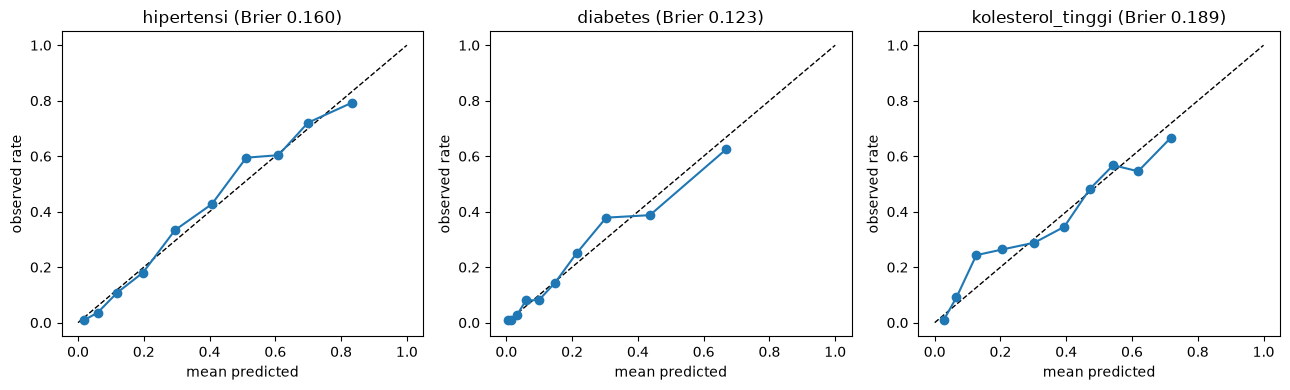

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (name, (y, p)) in zip(ax, P.items()):
    fp, mp = calibration_curve(y, p, n_bins=10, strategy='quantile')
    a.plot([0, 1], [0, 1], 'k--', lw=1); a.plot(mp, fp, 'o-')
    a.set(title=f'{name} (Brier {brier_score_loss(y, p):.3f})', xlabel='mean predicted', ylabel='observed rate')
plt.tight_layout(); plt.show()

**Calibration numbers.** ECE (10 quantile bins), calibration slope/intercept (logistic fit of label on logit(p); slope 1 and intercept 0 = perfect), Brier skill vs always predicting the prevalence. Out-of-fold train, val and test.
Then: does recalibration (Platt / isotonic fitted on out-of-fold train) help on test?

In [12]:
from sklearn.isotonic import IsotonicRegression
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
def ece(y, p, n=10):
    g = pd.DataFrame({'y': y, 'p': p, 'q': pd.qcut(p, n, duplicates='drop')}).groupby('q', observed=True).agg(y=('y', 'mean'), p=('p', 'mean'), n=('y', 'size'))
    return (g.n * (g.y - g.p).abs()).sum() / g.n.sum()
def get(split, name):
    x = {'train': tr, 'val': va, 'test': te}[split]; m = x[TG[name]].notna().values
    return x[TG[name]][m].values.astype(int), soft[split][f'p_{name}'][m].values

rows = []
for name in TG:
    for split in ['train', 'val', 'test']:
        y, p = get(split, name); lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
        b0 = brier_score_loss(y, np.full(len(y), y.mean()))
        rows.append(dict(target=name, split=split + (' (OOF)' if split == 'train' else ''), n=len(y), mean_pred=p.mean(), observed=y.mean(),
                         Brier=brier_score_loss(y, p), Brier_skill=1 - brier_score_loss(y, p) / b0, ECE=ece(y, p),
                         slope=lr.coef_[0, 0], intercept=lr.intercept_[0]))
print(pd.DataFrame(rows).round(3).to_string(index=False))

rows = []
for name in TG:
    ytr, ptr = get('train', name); yte, pte = get('test', name)
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(ptr).reshape(-1, 1), ytr).predict_proba(logit(pte).reshape(-1, 1))[:, 1]
    iso = IsotonicRegression(out_of_bounds='clip').fit(ptr, ytr).predict(pte)
    for tag, q in [('raw', pte), ('platt', platt), ('isotonic', iso)]:
        rows.append(dict(target=name, version=tag, Brier=brier_score_loss(yte, q), ECE=ece(yte, q), AUC=roc_auc_score(yte, q)))
print(); print(pd.DataFrame(rows).round(4).to_string(index=False))

           target       split    n  mean_pred  observed  Brier  Brier_skill   ECE  slope  intercept
       hipertensi train (OOF) 5192      0.370     0.370  0.170        0.272 0.028  0.879     -0.036
       hipertensi         val 1113      0.366     0.361  0.169        0.269 0.034  0.923     -0.054
       hipertensi        test 1109      0.375     0.381  0.160        0.323 0.027  1.050      0.048
         diabetes train (OOF) 5197      0.192     0.195  0.124        0.211 0.023  0.846     -0.130
         diabetes         val 1114      0.191     0.189  0.121        0.213 0.040  0.909     -0.105
         diabetes        test 1114      0.198     0.199  0.123        0.230 0.026  0.906     -0.079
kolesterol_tinggi train (OOF) 5167      0.351     0.350  0.185        0.188 0.025  0.865     -0.053
kolesterol_tinggi         val 1105      0.345     0.352  0.187        0.178 0.041  0.840     -0.027
kolesterol_tinggi        test 1105      0.347     0.350  0.189        0.170 0.044  0.816     -0.060


## 7b. Risk levels (rendah / sedang / tinggi)
Cut-offs are relative to each disease's prevalence in train: low < 0.5x prevalence, high >= 1.5x prevalence, rounded to 0.05. Fixed cut-offs (0.25 / 0.5) would mean different things per disease. Derived on train out-of-fold only; checked on val+test.

In [13]:
LV = {}
for name in TG:
    y, p = get('train', name); prev = y.mean()
    snap = lambda v: float(np.floor(v / 0.05 + 0.5) * 0.05)
    LV[name] = dict(prevalence=round(float(prev), 3), low_below=round(snap(0.5 * prev), 2), high_from=round(snap(1.5 * prev), 2))
json.dump(LV, open(OUT + 'risk_levels.json', 'w'), indent=1); print(json.dumps(LV))

rows = []
for name, c in LV.items():
    (yv, pv), (yt, pt) = get('val', name), get('test', name); y, p = np.r_[yv, yt], np.r_[pv, pt]
    lvl = np.where(p < c['low_below'], 'rendah', np.where(p >= c['high_from'], 'tinggi', 'sedang'))
    for L in ['rendah', 'sedang', 'tinggi']:
        m = lvl == L
        rows.append(dict(target=name, level=L, share_of_people=m.mean(), observed_rate=y[m].mean(), vs_prevalence=y[m].mean() / y.mean(), n=int(m.sum())))
print(pd.DataFrame(rows).round(3).to_string(index=False))

{"hipertensi": {"prevalence": 0.37, "low_below": 0.2, "high_from": 0.55}, "diabetes": {"prevalence": 0.195, "low_below": 0.1, "high_from": 0.3}, "kolesterol_tinggi": {"prevalence": 0.35, "low_below": 0.2, "high_from": 0.55}}
           target  level  share_of_people  observed_rate  vs_prevalence    n
       hipertensi rendah            0.360          0.062          0.169  800
       hipertensi sedang            0.335          0.416          1.122  745
       hipertensi tinggi            0.305          0.685          1.848  677
         diabetes rendah            0.467          0.030          0.153 1040
         diabetes sedang            0.282          0.228          1.172  628
         diabetes tinggi            0.251          0.462          2.380  560
kolesterol_tinggi rendah            0.346          0.107          0.305  765
kolesterol_tinggi sedang            0.417          0.412          1.174  922
kolesterol_tinggi tinggi            0.237          0.600          1.710  523


## 8. ONNX export and parity check (for the Raspberry Pi)

In [14]:
import onnxruntime as ort
Xt = te[FEATS].astype('float32').values
for name in TG:
    path = f'models/{name}.onnx'
    models[name].save_model(path, format='onnx')
    s = ort.InferenceSession(path); out = s.run(None, {s.get_inputs()[0].name: Xt})[1]
    p_onnx = np.array([r[1] for r in out]) if isinstance(out, list) else np.asarray(out)[:, 1]
    print(f'{name}: {os.path.getsize(path)/1024:.0f} KB, max |onnx - catboost| = {np.abs(p_onnx - soft["test"][f"p_{name}"].values).max():.1e}')

hipertensi: 677 KB, max |onnx - catboost| = 1.6e-07
diabetes: 677 KB, max |onnx - catboost| = 2.0e-07
kolesterol_tinggi: 675 KB, max |onnx - catboost| = 1.4e-07


## 9. Rule engine and result card
Deterministic layer between the models and the LLM. The LLM never computes numbers; it only reads this card.
Sources: blood pressure categories = AHA/ACC adult hypertension guideline table (as printed in the Merck Manual table citing *2025 AHA/ACC guideline, Hypertension 2025;82(10):e212-e316*; same cut-offs as 2017);
BMI and waist = Kemenkes decree HK.01.07/MENKES/509/2025 (Tables 3.1, 3.2; Asia-Pacific criteria), HDL < 40 (men) / < 50 (women) from its Table 3.4. Risk levels = section 7b.

In [15]:
LV = json.load(open(OUT + 'risk_levels.json'))
SESS = {n: ort.InferenceSession(f'models/{n}.onnx') for n in TG}
RANGES = {'age': (18, 120), 'bmi': (10, 80), 'sbp': (70, 260), 'dbp': (40, 150), 'waist': (40, 200), 'hdl': (10, 200)}
DISCLAIMER = ('Hasil ini adalah perkiraan risiko statistik dari data survei dewasa Amerika (NHANES), bukan diagnosis. '
              'Konsultasikan dengan dokter atau tenaga kesehatan untuk pemeriksaan dan keputusan medis.')

def bp_category(sbp, dbp):
    s = 3 if (sbp >= 140 or dbp >= 90) else 2 if (sbp >= 130 or dbp >= 80) else 1 if (sbp >= 120) else 0   # higher category wins
    return ['normal', 'meningkat (elevated)', 'hipertensi stage 1', 'hipertensi stage 2'][s]

def bmi_category(bmi):   # Asia-Pacific, Kemenkes 2025 table 3.1
    return ('berat badan kurang' if bmi < 18.5 else 'normal' if bmi < 23 else 'berat badan lebih' if bmi < 25
            else 'obesitas I' if bmi < 30 else 'obesitas II')

def risk_level(p, name):
    c = LV[name]; return 'rendah' if p < c['low_below'] else 'tinggi' if p >= c['high_from'] else 'sedang'

yesno = lambda v: 'tidak diketahui' if v is None or (isinstance(v, float) and np.isnan(v)) else ('ya' if v == 1 else 'tidak')

def predict_probs(x):
    row = np.array([[np.nan if x.get(f) is None else x[f] for f in FEATS]], dtype='float32')
    out = {}
    for n, s in SESS.items():
        r = s.run(None, {s.get_inputs()[0].name: row})[1]
        out[n] = float(r[0][1] if isinstance(r, list) else np.asarray(r)[0, 1])
    return out

def make_card(x, probs=None):
    warn, miss = [], [f for f in FEATS if x.get(f) is None or (isinstance(x.get(f), float) and np.isnan(x[f]))]
    for f, (lo, hi) in RANGES.items():
        v = x.get(f)
        if v is not None and not (isinstance(v, float) and np.isnan(v)) and not lo <= v <= hi:
            warn.append(f'nilai {f} di luar rentang wajar ({lo}-{hi}): {v}')
    if x['sbp'] <= x['dbp']: warn.append('tekanan darah sistolik tidak lebih besar dari diastolik, periksa input')
    if x['sbp'] >= 180 or x['dbp'] >= 120: warn.append('tekanan darah sangat tinggi: anjurkan segera ke fasilitas kesehatan')
    probs = probs or predict_probs(x)
    w, male = x.get('waist'), x['male'] == 1
    have_w = w is not None and not (isinstance(w, float) and np.isnan(w))
    return {
        'versi': 1,
        'pasien': {'umur': int(x['age']), 'jenis_kelamin': 'laki-laki' if male else 'perempuan', 'bmi': x['bmi'],
                   'td_sistolik': round(x['sbp']), 'td_diastolik': round(x['dbp']), 'pernah_merokok': yesno(x.get('smoker')),
                   'lingkar_pinggang_cm': w if have_w else None, 'hdl_mgdl': x['hdl'],
                   'riwayat_diabetes_keluarga': yesno(x.get('fam_dm')), 'riwayat_serangan_jantung_keluarga': yesno(x.get('fam_mi')),
                   'olahraga_berat_rekreasi': yesno(x.get('vig_rec')), 'olahraga_sedang_rekreasi': yesno(x.get('mod_rec'))},
        'kategori': {'tekanan_darah': bp_category(x['sbp'], x['dbp']), 'bmi': bmi_category(x['bmi']),
                     'lingkar_pinggang': 'tidak diketahui' if not have_w else ('di atas batas (obesitas sentral)' if w > (90 if male else 80) else 'normal'),
                     'hdl': 'rendah' if x['hdl'] < (40 if male else 50) else 'cukup'},
        'risiko': {n: {'probabilitas': round(p, 3), 'persen_perkiraan': '<5%' if p < 0.025 else '>95%' if p > 0.975 else f'{int(np.floor(p * 100 / 5 + 0.5) * 5)}%', 'tingkat': risk_level(p, n)} for n, p in probs.items()},
        'data_tidak_lengkap': miss, 'peringatan': warn, 'disclaimer': DISCLAIMER}

# unit tests
assert [bp_category(*v) for v in [(119, 79), (125, 79), (125, 81), (135, 95), (142, 91), (118, 92)]] ==     ['normal', 'meningkat (elevated)', 'hipertensi stage 1', 'hipertensi stage 2', 'hipertensi stage 2', 'hipertensi stage 2']
assert [bmi_category(v) for v in [18.4, 18.5, 22.9, 23.0, 24.9, 25.0, 29.9, 30.0]] ==     ['berat badan kurang', 'normal', 'normal', 'berat badan lebih', 'berat badan lebih', 'obesitas I', 'obesitas I', 'obesitas II']
assert [risk_level(p, 'diabetes') for p in [0.09, 0.10, 0.29, 0.30]] == ['rendah', 'sedang', 'sedang', 'tinggi']
r = te.iloc[0][FEATS].to_dict(); assert abs(predict_probs(r)['hipertensi'] - soft['test'].p_hipertensi.iloc[0]) < 1e-5
print('rule engine tests passed')

rule engine tests passed

Sample cards from train patients (probabilities are out-of-fold, as they will be in the KD data).

In [16]:
lv = pd.DataFrame({n: [risk_level(p, n) for p in soft['train'][f'p_{n}']] for n in TG})
ntinggi = (lv == 'tinggi').sum(axis=1); nrendah = (lv == 'rendah').sum(axis=1)
pick = {'semua rendah': nrendah == 3, 'campuran': (ntinggi == 0) & (nrendah <= 1), 'satu tinggi': ntinggi == 1,
        'dua tinggi': ntinggi == 2, 'semua tinggi': ntinggi == 3,
        'TD sangat tinggi': (tr.sbp >= 180) | (tr.dbp >= 120), 'data kosong': tr.fam_dm.isna() | tr.waist.isna()}
cards = []
for k, m in pick.items():
    for i in tr[m.values].sample(min(2 if k in ('semua rendah', 'campuran', 'satu tinggi') else 1, int(m.sum())), random_state=0).index:
        x = {f: (None if pd.isna(tr.loc[i, f]) else float(tr.loc[i, f])) for f in FEATS}
        c = make_card(x, {n: float(soft['train'].loc[i, f'p_{n}']) for n in TG}); c['id_pasien'] = int(tr.loc[i, 'SEQN']); c['jenis_contoh'] = k
        cards.append(c)
json.dump(cards, open(OUT + 'cards_sample.json', 'w'), indent=1, ensure_ascii=False)
print(len(cards), 'sample cards saved to data/final/cards_sample.json'); print(json.dumps(cards[0], indent=1, ensure_ascii=False))

10 sample cards saved to data/final/cards_sample.json
{
 "versi": 1,
 "pasien": {
  "umur": 35,
  "jenis_kelamin": "laki-laki",
  "bmi": 25.2,
  "td_sistolik": 120,
  "td_diastolik": 68,
  "pernah_merokok": "tidak",
  "lingkar_pinggang_cm": 88.0,
  "hdl_mgdl": 46.0,
  "riwayat_diabetes_keluarga": "tidak",
  "riwayat_serangan_jantung_keluarga": "tidak",
  "olahraga_berat_rekreasi": "ya",
  "olahraga_sedang_rekreasi": "ya"
 },
 "kategori": {
  "tekanan_darah": "normal",
  "bmi": "obesitas I",
  "lingkar_pinggang": "normal",
  "hdl": "cukup"
 },
 "risiko": {
  "hipertensi": {
   "probabilitas": 0.062,
   "persen_perkiraan": "5%",
   "tingkat": "rendah"
  },
  "diabetes": {
   "probabilitas": 0.009,
   "persen_perkiraan": "<5%",
   "tingkat": "rendah"
  },
  "kolesterol_tinggi": {
   "probabilitas": 0.143,
   "persen_perkiraan": "15%",
   "tingkat": "rendah"
  }
 },
 "data_tidak_lengkap": [],
 "peringatan": [],
 "disclaimer": "Hasil ini adalah perkiraan risiko statistik dari data survei de

Export cards for ALL train patients (used by the KD notebook, which runs on Colab and needs no models). Probabilities are out-of-fold.

In [17]:
os.makedirs(OUT + 'kd', exist_ok=True)
allc = []
for i in tr.index:
    x = {f: (None if pd.isna(tr.loc[i, f]) else float(tr.loc[i, f])) for f in FEATS}
    pr = {n: float(soft['train'].loc[i, f'p_{n}']) for n in TG}
    if any(np.isnan(v) for v in pr.values()):   # no OOF value when that label is missing (row not used to train that target): use the final model
        fb = predict_probs(x); pr = {n: (fb[n] if np.isnan(v) else v) for n, v in pr.items()}
    c = make_card(x, pr); c['id_pasien'] = int(tr.loc[i, 'SEQN']); allc.append(c)
json.dump(allc, open(OUT + 'kd/cards_train.json', 'w'), ensure_ascii=False)
print(len(allc), 'train cards ->', OUT + 'kd/cards_train.json', f'({os.path.getsize(OUT + "kd/cards_train.json")/1e6:.1f} MB)')

5197 train cards -> data/final/kd/cards_train.json (5.4 MB)
